# DSA4213 Assignment 1, Part III: Downstream representation analysis

Task: AG News topic classification with 4 classes (World, Sports, Business, Sci/Tech).

Representations I compare (all from frozen models trained in Parts I and II, with the same classifier and procedure for each):
* Mean-pooled top-layer hidden states from the RNN, LSTM-A (random embeddings), LSTM-B (word2vec, frozen), LSTM-C (GloVe, frozen) and the Transformer.
* Last-state pooling for LSTM-A, to compare pooling methods.
* A baseline with no language model: bag-of-embeddings (the average of the input embedding vectors) for the A, B and C embedding tables.

Classifier: `StandardScaler` + logistic regression, with C chosen on validation accuracy. The test set is only used once.

## 1. Setup

The vocabulary and model classes are copied unchanged from Parts I and II. The vocabulary has to be identical to load the checkpoints and encode AG News.

In [ ]:
import os

#Detect Google Colab or localhost
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = "/content/drive/MyDrive/DSA4213 Assignment/results"
else:
    SAVE_DIR = "results"          # a local folder next to the notebook

os.makedirs(SAVE_DIR, exist_ok=True)
# When running locally, reuse the timings/features saved from my Colab (T4) run instead of
# re-measuring them on a slower machine. In Colab everything is measured again.
REUSE_SAVED = not IN_COLAB

print("Running in Colab:", IN_COLAB, "| Saving to:", SAVE_DIR, "| Reusing saved results:", REUSE_SAVED)

Mounted at /content/drive
Running in Colab: True | Saving to: /content/drive/MyDrive/DSA4213 Assignment/results | Reusing saved results: False


In [ ]:
#import, random seed and GPU
%pip install -q datasets scikit-learn

import matplotlib.pyplot as plt
import random, math, time
from collections import Counter
import numpy as np
import torch
from datasets import load_dataset
import json, re, html

SEED = 42 #fixes the randomness so every run gives the same results (for reproducibility)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


In [ ]:
#load wikitext-2
ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

print(ds)

for i in range(1, 8):
    print(repr(ds["train"][i]["text"]))


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
' = Valkyria Chronicles III = \n'
''
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " 

In [ ]:
#tokenize (split text into words)
def tokenize_split(split):
    tokens = []
    for line in ds[split]["text"]:
        line = line.strip().lower()
        if line == "":
            continue                     # skip empty lines
        tokens.extend(line.split())      # split on whitespace
        tokens.append("<eos>")           # mark the end of each line
    return tokens

train_tokens = tokenize_split("train")
val_tokens   = tokenize_split("validation")
test_tokens  = tokenize_split("test")

print(len(train_tokens), len(val_tokens), len(test_tokens))
print(train_tokens[:30])


2075677 216347 244102
['=', 'valkyria', 'chronicles', 'iii', '=', '<eos>', 'senjō', 'no', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'of', 'the', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'to']


In [ ]:
#build the vocabulary (from train only) and convert words into IDs
MIN_FREQ = 3 #keep words that appear at least 3 times in train
counts = Counter(train_tokens)

itos = ["<unk>", "<eos>"] + sorted(w for w, c in counts.items() if c >= MIN_FREQ and w != "<eos>") #index-to-string, a list to match each word to their position in the list
stoi = {w: i for i, w in enumerate(itos)} #string-to-index, a dictionary built from itos that goes the other way
V = len(itos)
print("Vocab size:", V)

def encode(tokens):
    unk = stoi["<unk>"]
    return [stoi.get(w, unk) for w in tokens]

train_ids = encode(train_tokens)
val_ids   = encode(val_tokens)
test_ids  = encode(test_tokens)

#oov rate = out of vocab rate is the percentage of words in a piece of text that are not in the vocabulary so they are replaced with <unk>
for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]:
    print(f"{name}: {len(ids)} tokens, OOV rate = {ids.count(0)/len(ids):.2%}")


Vocab size: 29572
train: 2075677 tokens, OOV rate = 2.25%
val: 216347 tokens, OOV rate = 4.72%
test: 244102 tokens, OOV rate = 5.62%


In [ ]:
#settings and the model class
import torch.nn as nn

# ---- Shared hyperparameters for ALL neural models ----
EMB_DIM = 100        # matches GloVe 100d (needed for Part 2)
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT = 0.3
EPOCHS = 10
LR = 1e-3
CLIP = 1.0

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

BPTT = 64

class RecurrentLM(nn.Module):
    def __init__(self, vocab_size, cell="lstm", emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM,
                 num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)
        rnn_class = nn.LSTM if cell == "lstm" else nn.RNN
        self.rnn = rnn_class(emb_dim, hidden_dim, num_layers=num_layers,
                             dropout=dropout, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        emb = self.drop(self.embedding(x))   # (B, T)      -> (B, T, 100)
        out, _ = self.rnn(emb)               # (B, T, 100) -> (B, T, 256)
        return self.fc(self.drop(out))       # (B, T, 256) -> (B, T, 29572)


In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())


In [ ]:
#the transformer model
class TransformerLM(nn.Module):
    def __init__(self, vocab_size, emb_dim=EMB_DIM, d_model=HIDDEN_DIM, nhead=4,
                 num_layers=NUM_LAYERS, ff_dim=512, dropout=DROPOUT, max_len=BPTT):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)     # word -> 100 numbers
        self.in_proj = nn.Linear(emb_dim, d_model)              # 100 -> 256
        self.pos = nn.Embedding(max_len, d_model)               # position 0..63 -> 256 numbers
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff_dim, dropout,
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers, norm=nn.LayerNorm(d_model),
                                             enable_nested_tensor=False)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, vocab_size)                # 256 -> score per word

    def forward(self, x):
        T = x.size(1)
        positions = torch.arange(T, device=x.device)
        h = self.in_proj(self.drop(self.embedding(x))) + self.pos(positions)
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)  # causal mask
        h = self.encoder(self.drop(h), mask=mask, is_causal=True)
        return self.fc(self.drop(h))


In [ ]:
#load AG news and make the splits
ag = load_dataset("fancyzhx/ag_news")
LABELS = ag["train"].features["label"].names
print(LABELS)
print(ag)

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(ag["train"]))
cls_train = ag["train"].select(perm[:10000].tolist())
cls_val   = ag["train"].select(perm[10000:12000].tolist())
cls_test  = ag["test"]

for name, d in [("train", cls_train), ("val", cls_val), ("test", cls_test)]:
    print(name, len(d), "label counts:", np.bincount(d["label"]))

for i in range(3):
    print(LABELS[cls_train[i]["label"]], "|", cls_train[i]["text"])


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

['World', 'Sports', 'Business', 'Sci/Tech']
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
train 10000 label counts: [2530 2528 2407 2535]
val 2000 label counts: [479 506 493 522]
test 7600 label counts: [1900 1900 1900 1900]
World | Bangladesh paralysed by strikes Opposition activists have brought many towns and cities in Bangladesh to a halt, the day after 18 people died in explosions at a political rally.
Sports | Desiring Stability Redskins coach Joe Gibbs expects few major personnel changes in the offseason and wants to instill a culture of stability in Washington.
World | Will Putin #39;s Power Play Make Russia Safer? Outwardly, Russia has not changed since the barrage of terrorist attacks that culminated in the school massacre in Beslan on Sept.


* `fancyzhx/ag_news` is AG News on the Hugging Face Hub.
* My train (10,000) and validation (2,000) sets are different rows of the shuffled AG News training set (seed 42), so they don't overlap. The test set is the official 7,600-example test set, and I never use it to choose anything.
* All three splits are balanced (about 25% per class), so accuracy is a fair metric. I report macro-F1 as well.

In [ ]:
## tokenize like WikiText and check OOV
MAX_LEN = 64   # same context length as the LMs (the Transformer can't go beyond 64)

def clean_tokenize(text):
    text = html.unescape(text).replace("\\", " ")
    text = text.replace("#39;", "'").replace("#36;", "$")
    text = re.sub(r"#\d+;", " ", text)                    # remove leftover HTML codes
    text = text.lower()
    text = re.sub(r"(?<=\w)-(?=\w)", " @-@ ", text)       # WikiText writes hyphens as @-@
    return re.findall(r"@-@|'s|\w+|[^\w\s]", text)        # words, 's, punctuation as separate tokens

def encode_dataset(d):
    tok = [clean_tokenize(t) for t in d["text"]]
    ids = [encode(t)[:MAX_LEN] for t in tok]
    return tok, ids, np.array(d["label"])

tr_tok, tr_ids, y_train = encode_dataset(cls_train)
va_tok, va_ids, y_val   = encode_dataset(cls_val)
te_tok, te_ids, y_test  = encode_dataset(cls_test)

print("Example:")
print("  raw:   ", cls_train[0]["text"])
print("  tokens:", tr_tok[0])
print("  as LM sees it:", " ".join(itos[i] for i in tr_ids[0]))

lens = np.array([len(t) for t in tr_tok])
all_ids = [i for s in tr_ids for i in s]
print(f"\nTokens per text: mean {lens.mean():.1f}, median {np.median(lens):.0f}, max {lens.max()}")
print(f"Texts truncated at {MAX_LEN} tokens: {(lens > MAX_LEN).mean():.1%}")
print(f"OOV rate (AG News train, WikiText vocab): {all_ids.count(0) / len(all_ids):.2%}")


Example:
  raw:    Bangladesh paralysed by strikes Opposition activists have brought many towns and cities in Bangladesh to a halt, the day after 18 people died in explosions at a political rally.
  tokens: ['bangladesh', 'paralysed', 'by', 'strikes', 'opposition', 'activists', 'have', 'brought', 'many', 'towns', 'and', 'cities', 'in', 'bangladesh', 'to', 'a', 'halt', ',', 'the', 'day', 'after', '18', 'people', 'died', 'in', 'explosions', 'at', 'a', 'political', 'rally', '.']
  as LM sees it: bangladesh <unk> by strikes opposition activists have brought many towns and cities in bangladesh to a halt , the day after 18 people died in explosions at a political rally .

Tokens per text: mean 45.4, median 44, max 245
Texts truncated at 64 tokens: 6.8%
OOV rate (AG News train, WikiText vocab): 7.19%


* Tokenisation: WikiText-2 is already split (`word , word`) but AG News is raw text, so I use a regex to split punctuation into separate tokens and write hyphens as `@-@`, to match what the LMs saw in training. I also clean up HTML codes like `#39;` (apostrophe) and `#36;` ($).
* Truncation to 64 tokens: the LMs were trained with a 64-token context and the Transformer's position table only has 64 entries. 6.8% of the texts get cut.
* The OOV rate is 7.19%, higher than WikiText-2 test (5.6%), because news uses words that aren't in the Wikipedia vocabulary (for example the British spelling *paralysed* becomes `<unk>`).

In [ ]:
#feature extraction functions
@torch.no_grad()
def token_states(model, x):
    """Top-layer hidden state at every position: shape (B, T, 256)."""
    model.eval()
    if isinstance(model, RecurrentLM):
        out, _ = model.rnn(model.embedding(x))
        return out
    T = x.size(1)
    h = model.in_proj(model.embedding(x)) + model.pos(torch.arange(T, device=x.device))
    mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
    return model.encoder(h, mask=mask, is_causal=True)

@torch.no_grad()
def extract_features(model, seqs, batch_size=256):
    """Returns (mean-pooled, last-state) features, each of shape (n_texts, 256)."""
    mean_feats, last_feats = [], []
    for s in range(0, len(seqs), batch_size):
        batch = seqs[s : s + batch_size]
        lengths = torch.tensor([len(b) for b in batch], device=device)
        T = int(lengths.max())
        x = torch.zeros(len(batch), T, dtype=torch.long, device=device)    # pad on the right
        for i, b in enumerate(batch):
            x[i, : len(b)] = torch.tensor(b, device=device)
        h = token_states(model, x)
        real = (torch.arange(T, device=device)[None, :] < lengths[:, None]).float()  # 1 = real token, 0 = padding
        mean = (h * real.unsqueeze(-1)).sum(1) / lengths[:, None]
        last = h[torch.arange(len(batch), device=device), lengths - 1]
        mean_feats.append(mean.cpu())
        last_feats.append(last.cpu())
    return torch.cat(mean_feats).numpy(), torch.cat(last_feats).numpy()


* `token_states` repeats each model's forward pass but stops before the output layer, so it returns the 256-d top-layer hidden state at every position.
* Padding: texts are padded on the right to the longest text in the batch. This is safe because (1) all my LMs are causal, so padding after a token can't change that token's hidden state, and (2) the `real` mask leaves padding out of the mean, and `lengths - 1` picks the last real token for last-state pooling.
* Mean pooling averages the hidden states of all the real tokens. Last-state pooling takes the hidden state at the final real token.

In [ ]:
# extract features
MODEL_SPECS = {
    "RNN":             ("rnn",               lambda: RecurrentLM(V, cell="rnn")),
    "LSTM-A (random)": ("lstm",              lambda: RecurrentLM(V, cell="lstm")),
    "LSTM-B (w2v)":    ("lstm_w2v_frozen",   lambda: RecurrentLM(V, cell="lstm")),
    "LSTM-C (GloVe)":  ("lstm_glove_frozen", lambda: RecurrentLM(V, cell="lstm")),
    "Transformer":     ("transformer",       lambda: TransformerLM(V)),
}

feat_path = os.path.join(SAVE_DIR, "part3_features.npz")
if REUSE_SAVED and os.path.exists(feat_path):
    # load the features extracted in my Colab run instead of extracting them again
    saved = np.load(feat_path)
    features = {}
    for key in saved.files:                      # keys look like "LSTM-A (random) | mean__train"
        name, split = key.rsplit("__", 1)
        features.setdefault(name, []).append(saved[key])
    features = {k: tuple(v) for k, v in features.items()}
    print("Loaded saved features:", list(features))
else:
    features = {}
    for name, (ckpt, build) in MODEL_SPECS.items():
        model = build()
        model.load_state_dict(torch.load(os.path.join(SAVE_DIR, f"{ckpt}.pt"), map_location=device))
        model.to(device)
        t0 = time.time()
        tr_mean, tr_last = extract_features(model, tr_ids)
        va_mean, va_last = extract_features(model, va_ids)
        te_mean, te_last = extract_features(model, te_ids)
        features[f"{name} | mean"] = (tr_mean, va_mean, te_mean)
        if name == "LSTM-A (random)":
            features[f"{name} | last"] = (tr_last, va_last, te_last)
        print(f"{name}: features {tr_mean.shape}, extracted in {time.time() - t0:.1f}s")

    np.savez(os.path.join(SAVE_DIR, "part3_features.npz"),
             **{f"{k}__{s}": v for k, vals in features.items() for s, v in zip(["train", "val", "test"], vals)})


RNN: features (10000, 256), extracted in 2.5s
LSTM-A (random): features (10000, 256), extracted in 1.8s
LSTM-B (w2v): features (10000, 256), extracted in 4.2s
LSTM-C (GloVe): features (10000, 256), extracted in 4.0s
Transformer: features (10000, 256), extracted in 3.7s


Each frozen LM checkpoint is loaded, features are extracted for all three splits, and they are saved to `part3_features.npz`. I ran this part on a CPU runtime.

## 2. Classifiers and analysis

### Bag-of-embeddings baseline (no LM)

To separate what the input embeddings contribute from what the LM layers contribute, I also represent each text as the average of its input embedding vectors. I read the tables from the same checkpoints: A was learned during LM training, and B (word2vec) and C (GloVe) are unchanged because they were frozen.

In [ ]:
def bag_of_embeddings(emb, seqs):
    """Average the embedding vectors of each text's tokens (no LM involved)."""
    return np.stack([emb[s].mean(0) for s in seqs])

for name, ckpt in [("Emb-A (learned)", "lstm"),
                   ("Emb-B (w2v)", "lstm_w2v_frozen"),
                   ("Emb-C (GloVe)", "lstm_glove_frozen")]:
    emb = torch.load(os.path.join(SAVE_DIR, f"{ckpt}.pt"), map_location="cpu")["embedding.weight"].numpy()
    features[f"{name} | bag-of-emb"] = tuple(bag_of_embeddings(emb, s) for s in (tr_ids, va_ids, te_ids))
    print(name, emb.shape)


Emb-A (learned) (29572, 100)
Emb-B (w2v) (29572, 100)
Emb-C (GloVe) (29572, 100)


In [ ]:
# train one classifier per representation
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import pandas as pd

C_GRID = [0.01, 0.1, 1, 10]

def fit_best(Xtr, Xva):
    """Try each C, keep the one with the best validation accuracy."""
    best = None
    for C in C_GRID:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, random_state=SEED))
        clf.fit(Xtr, y_train)
        acc = accuracy_score(y_val, clf.predict(Xva))
        if best is None or acc > best[0]:
            best = (acc, C, clf)
    return best

cls_rows, test_preds = {}, {}
for name, (Xtr, Xva, Xte) in features.items():
    val_acc, C, clf = fit_best(Xtr, Xva)
    pred = clf.predict(Xte)
    test_preds[name] = pred
    cls_rows[name] = {
        "best C": C,
        "Val acc": round(val_acc, 4),
        "Test acc": round(accuracy_score(y_test, pred), 4),
        "Test macro-F1": round(f1_score(y_test, pred, average="macro"), 4),
    }
    print(name, cls_rows[name])


RNN | mean {'best C': 0.01, 'Val acc': 0.6515, 'Test acc': 0.6614, 'Test macro-F1': 0.6587}
LSTM-A (random) | mean {'best C': 0.01, 'Val acc': 0.6425, 'Test acc': 0.6441, 'Test macro-F1': 0.6415}
LSTM-A (random) | last {'best C': 0.01, 'Val acc': 0.568, 'Test acc': 0.5849, 'Test macro-F1': 0.5806}
LSTM-B (w2v) | mean {'best C': 0.1, 'Val acc': 0.7645, 'Test acc': 0.7675, 'Test macro-F1': 0.7665}
LSTM-C (GloVe) | mean {'best C': 0.1, 'Val acc': 0.84, 'Test acc': 0.8233, 'Test macro-F1': 0.823}
Transformer | mean {'best C': 0.1, 'Val acc': 0.73, 'Test acc': 0.7284, 'Test macro-F1': 0.7267}
Emb-A (learned) | bag-of-emb {'best C': 0.01, 'Val acc': 0.6145, 'Test acc': 0.6199, 'Test macro-F1': 0.6185}
Emb-B (w2v) | bag-of-emb {'best C': 0.01, 'Val acc': 0.789, 'Test acc': 0.7759, 'Test macro-F1': 0.7748}
Emb-C (GloVe) | bag-of-emb {'best C': 0.01, 'Val acc': 0.8955, 'Test acc': 0.8716, 'Test macro-F1': 0.8712}


* I use the same classifier and procedure for every representation: standardise the features, then logistic regression.
* C (how strongly the classifier is regularised) is chosen from {0.01, 0.1, 1, 10} by validation accuracy, and the test set is only used once at the end.
* The language models stay frozen and only the classifier is trained.

In [ ]:
# results table, plus the LM perplexity comparison
from scipy.stats import spearmanr

with open(os.path.join(SAVE_DIR, "results.json")) as f:
    r1 = json.load(f)
p2 = pd.read_csv(os.path.join(SAVE_DIR, "part2_table.csv"), index_col=0)

lm_ppl = {
    "RNN":             r1["rnn"]["test_ppl"],
    "LSTM-A (random)": r1["lstm"]["test_ppl"],
    "Transformer":     r1["transformer"]["test_ppl"],
    "LSTM-B (w2v)":    float(p2.loc["B: word2vec, frozen", "Test PPL"]),
    "LSTM-C (GloVe)":  float(p2.loc["C: GloVe, frozen", "Test PPL"]),
}

table3 = pd.DataFrame(cls_rows).T
table3.insert(0, "LM test PPL", [round(lm_ppl.get(k.split(" | ")[0], float("nan")), 1) for k in table3.index])
table3 = table3.sort_values("Test acc", ascending=False)
print(table3.to_string())
table3.to_csv(os.path.join(SAVE_DIR, "part3_table.csv"))

# Does a better LM (lower PPL) give better features? (mean-pooled models only)
mean_rows = table3[table3.index.str.endswith("| mean")]
rho, p = spearmanr(mean_rows["LM test PPL"], mean_rows["Test acc"])
print(f"\nSpearman correlation (LM PPL vs test acc, n={len(mean_rows)}): rho = {rho:.2f} (p = {p:.2f})")
print("Negative rho = lower perplexity goes with higher accuracy.")
print("LM ranking (best→worst):        ", list(mean_rows.sort_values("LM test PPL").index))
print("Downstream ranking (best→worst):", list(mean_rows.sort_values("Test acc", ascending=False).index))


                              LM test PPL  best C  Val acc  Test acc  Test macro-F1
Emb-C (GloVe) | bag-of-emb            NaN    0.01   0.8955    0.8716         0.8712
LSTM-C (GloVe) | mean               172.9    0.10   0.8400    0.8233         0.8230
Emb-B (w2v) | bag-of-emb              NaN    0.01   0.7890    0.7759         0.7748
LSTM-B (w2v) | mean                 165.2    0.10   0.7645    0.7675         0.7665
Transformer | mean                  177.7    0.10   0.7300    0.7284         0.7267
RNN | mean                          200.5    0.01   0.6515    0.6614         0.6587
LSTM-A (random) | mean              178.2    0.01   0.6425    0.6441         0.6415
Emb-A (learned) | bag-of-emb          NaN    0.01   0.6145    0.6199         0.6185
LSTM-A (random) | last              178.2    0.01   0.5680    0.5849         0.5806

Spearman correlation (LM PPL vs test acc, n=5): rho = -0.80 (p = 0.10)
Negative rho = lower perplexity goes with higher accuracy.
LM ranking (best→worst):     

* I put the LM test perplexity next to each downstream score so the two rankings can be compared directly.
* Spearman's ρ measures how well the rankings agree (−1 means lower perplexity always gives higher accuracy, 0 means no relation). With only 5 models this is just an indication, not proof.

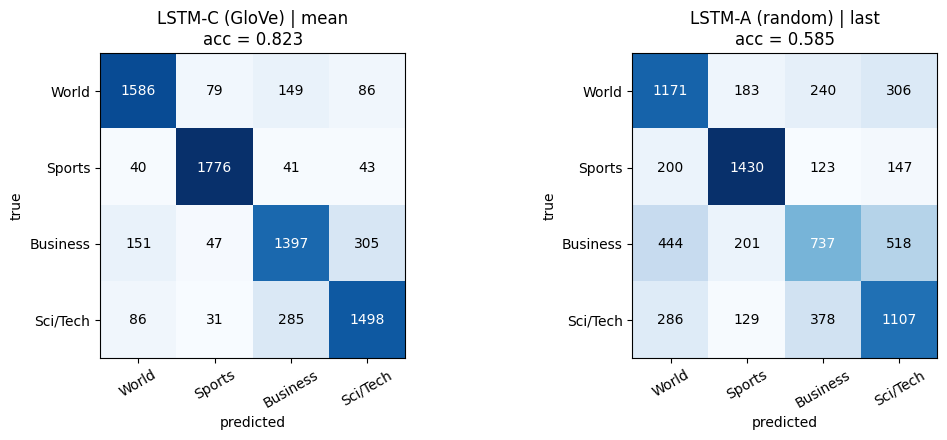

In [ ]:
#confusion matrices (best LM representation vs worst representation)
best_name = "LSTM-C (GloVe) | mean"
worst_name = table3.index[-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, [best_name, worst_name]):
    cm = confusion_matrix(y_test, test_preds[name])
    ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(4)); ax.set_xticklabels(LABELS, rotation=30)
    ax.set_yticks(range(4)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{name}\nacc = {table3.loc[name, 'Test acc']:.3f}")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "part3_confusion.png"), dpi=150)
plt.show()


Rows are the true classes and columns are the predicted classes. For the best LM representation, Sports is the easiest class (1,776 of 1,900 correct) and most mistakes are between Business and Sci/Tech. The last-state LSTM-A features mix up every pair of classes much more often.

In [ ]:
#error analysis
best_pred = test_preds[best_name]
wrong = np.where(best_pred != y_test)[0]
right = np.where(best_pred == y_test)[0]

def oov_rate(idx):
    toks = [t for i in idx for t in te_ids[i]]
    return toks.count(0) / len(toks)

print(f"Best representation: {best_name}  |  errors: {len(wrong)} / {len(y_test)}")
print(f"OOV rate in misclassified texts: {oov_rate(wrong):.2%}")
print(f"OOV rate in correct texts:       {oov_rate(right):.2%}")

print("\nMost common confusions (true → predicted):")
pairs = Counter((LABELS[y_test[i]], LABELS[best_pred[i]]) for i in wrong)
for (t, p_), c in pairs.most_common(5):
    print(f"  {t:9s} → {p_:9s}: {c}")

print("\n10 misclassified examples:")
rng_err = np.random.default_rng(SEED)
for i in rng_err.choice(wrong, 10, replace=False):
    print(f"\n  TRUE {LABELS[y_test[i]]:9s} PRED {LABELS[best_pred[i]]:9s}")
    print("   ", cls_test[int(i)]["text"][:200])
    print("    as LM saw it:", " ".join(itos[t] for t in te_ids[i][:30]), "...")


Best representation: LSTM-C (GloVe) | mean  |  errors: 1343 / 7600
OOV rate in misclassified texts: 7.09%
OOV rate in correct texts:       7.17%

Most common confusions (true → predicted):
  Business  → Sci/Tech : 305
  Sci/Tech  → Business : 285
  Business  → World    : 151
  World     → Business : 149
  Sci/Tech  → World    : 86

10 misclassified examples:

  TRUE World     PRED Sports   
    Dream Team Leads Spain 44-42 at Halftime ATHENS, Greece - As expected, the U.S. men's basketball team had its hands full in a quarterfinal game against Spain on Thursday...
    as LM saw it: dream team leads spain 44 @-@ 42 at halftime athens , greece - as expected , the u . s . men 's basketball team had its hands full in ...

  TRUE Sci/Tech  PRED Business 
    Press review 0850CET--The seizure of fake Nike sportswear by the Customs Department was one of the main stories on Wednesday #39;s newspapers. L-Orizzont published 
    as LM saw it: press review <unk> - - the seizure of fake nike <unk>

* I compare the OOV rate in wrongly and correctly classified texts to check if missing words cause the errors.
* The most common confusions show which class pairs get mixed up most.
* I print ten random misclassified texts together with the tokens the LM actually saw, to look at the errors by hand.

## 3. Interpretation

| Representation | LM test PPL | Test acc | Macro-F1 |
|---|---|---|---|
| Emb-C (GloVe), bag-of-embeddings | - | **87.2%** | 0.871 |
| LSTM-C (GloVe), mean | 172.9 | 82.4% | 0.823 |
| Emb-B (word2vec), bag-of-embeddings | - | 77.6% | 0.775 |
| LSTM-B (word2vec), mean | 165.2 | 76.7% | 0.766 |
| Transformer, mean | 177.7 | 72.8% | 0.726 |
| RNN, mean | 200.5 | 66.1% | 0.658 |
| LSTM-A (random), mean | 178.2 | 64.4% | 0.642 |
| Emb-A (learned), bag-of-embeddings | - | 62.0% | 0.619 |
| LSTM-A (random), last | 178.2 | 58.5% | 0.581 |

Random guessing would get 25%. Accuracy and macro-F1 are almost the same because the classes are balanced.

What I observed:
1. The embedding choice matters most. Among the LM representations, the two frozen-embedding LSTMs come 1st and 2nd. LSTM-C beats LSTM-A by 18 points with the same architecture and similar perplexity.
2. The LM layers add little on top of the input embeddings. Just averaging the GloVe vectors (87.2%) beats every LM representation, and passing them through the trained LSTM lowers accuracy to 82.4% (4.8 points worse). For word2vec the LSTM is 0.9 points worse, and only for the weakest (learned) embeddings does it help (2.4 points better). The embedding ranking (GloVe > word2vec > learned) is the same with or without the LM.
3. Perplexity only loosely predicts the downstream ranking (Spearman ρ = −0.80, p = 0.10, n = 5). Where they disagree: LSTM-A and the Transformer have almost the same perplexity (178.2 vs 177.7) but are 8.4 accuracy points apart; word2vec has the better perplexity but GloVe has the better accuracy; and the RNN has the worst perplexity but slightly beats LSTM-A.
4. Mean pooling beats last-state pooling for LSTM-A (64.4% vs 58.5%).

Possible reasons (not tested):
* GloVe was trained on Wikipedia and Gigaword newswire, and AG News is news. The same news-style meanings that hurt GloVe on WikiText-2 perplexity in Part II (like *game* meaning *season, match*) help it on news classification. So how useful extra pre-training data is depends on whether its domain matches the task.
* Predicting the next word on WikiText-2 mostly rewards local, grammatical information, so the LM hidden states may change or lose topic information that a linear classifier could read straight from the input vectors.
* With random embeddings, rare topic words (companies, places) get very few updates in 10 epochs, while pre-trained vectors give them meaningful values from the start.
* The last hidden state of a left-to-right model mostly reflects the last few tokens (often generic, like "... said on tuesday ."), while mean pooling also covers the headline, which carries most of the topic.

Error analysis (LSTM-C mean, 1,340 of 7,600 wrong):
* Business vs Sci/Tech accounts for 588 errors (44%) and Business vs World for 299 (22%). These topics really do overlap (tech companies, trade and economic policy).
* Missing words don't explain the errors: the OOV rate is 7.09% in the wrong texts and 7.17% in the correct ones.
* Types of errors in the examples: texts that are ambiguous or arguably mislabelled (an Olympic field hockey report labelled World but predicted Sports, a Nepal tourism blockade labelled Business but predicted World), texts with words from another topic (a track-and-field interview full of media words, Sports predicted as Sci/Tech), and errors with no clear reason (a US-Australia free trade deadline predicted as Sports).

Limitations: single seed; only a linear classifier on frozen features; LMs trained for 10 epochs on 2M tokens; some AG News texts still contain HTML tags (`&lt;b&gt;`) and `quot;` codes; 6.8% of texts are truncated to 64 tokens.

**Overall:** in this task, better next-word prediction did not lead to better topic representations. Most of the topic information comes from the input embeddings: averaging frozen GloVe vectors beat every language model representation, and the perplexity and downstream rankings only loosely agreed.